# Qué nos dice el perfil eléctrico de ayer sobre el de mañana

**Pregunta:** ¿Cuánto explica la repetición de un perfil diario en un extracto eléctrico real y qué ocurre cuando se equivoca el período o cambia el nivel?


## Objetivos

Una referencia estacional permite inspeccionar una decisión de pronóstico. En una serie eléctrica horaria, pregunta si la lectura a esta hora de mañana se parecerá a la lectura de la misma fase del día anterior. Es una hipótesis concreta sobre la rutina de un cliente. Explica más que atribuir un error bajo al éxito inespecífico de un modelo grande. Inspeccionaremos el eje temporal, pronosticaremos un bloque reservado y distinguiremos el error de predicción de la escala histórica empleada para expresarlo.

Usaremos al cliente MT_010 de la colección eléctrica de UCI, en lugar de una curva de demanda simulada. Es un extracto breve y seleccionado: su desempeño no establece precisión para otros clientes, estaciones, tarifas o contextos operacionales. Después agregaremos un cambio de nivel expresamente sintético al extracto auténtico. La intervención responde una pregunta sobre el mecanismo: ¿durante cuánto tiempo una regla que copia el día anterior sigue utilizando observaciones del régimen previo? No representa otro acontecimiento observado en el registro del cliente.

Al terminar deberías poder calcular la primera predicción mirando un valor anterior, explicar por qué la banda se ensancha en horizontes posteriores e identificar qué observaciones utiliza cada medida. También deberías poder sustituir el CSV por una serie propia de frecuencia regular sin cambiar el significado del denominador del error. Estas distinciones preparan la interpretación de los métodos más elaborados que presenta ChronoScope.


## Preparación

La lección llama la API publicada de PreqTS 0.3.0. Instala estas dependencias directas con sus versiones exactas en el entorno aislado de notebooks del repositorio antes de abrir el cuaderno. La ejecución no instala paquetes.

```text
pip install numpy==2.4.6
pip install matplotlib==3.10.8
pip install preqts==0.3.0
```

NumPy aporta los arreglos, Matplotlib las figuras y PreqTS la implementación del pronóstico y de la evaluación secuencial. Ninguna celda copia un pronosticador. Los intervalos empíricos de este paquete difieren de los intervalos gaussianos de residuos del método ligero del atlas de ChronoScope; compartir el nombre SeasonalNaive no vuelve idénticos ambos algoritmos de intervalos.


In [1]:
# Import the released API; the lesson does not install or redefine a method.
from pathlib import Path
import csv
from datetime import datetime
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from preqts import SeasonalNaive, Stream, run_prequential
from preqts.metrics import seasonal_naive_mae
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "VERSION").is_file())
plt.rcParams.update({"figure.figsize": (9, 3), "figure.dpi": 95, "font.size": 10})
for package in ("numpy", "matplotlib", "preqts"):
    print(package, importlib.metadata.version(package))
words = {'cut': 'Origen del pronóstico',
 'time': 'Hora local registrada',
 'value': 'Suma horaria (lecturas originales en kW)',
 'history': 'Historia disponible',
 'actual': 'Observaciones posteriores',
 'forecast': 'Ciclo diario repetido',
 'interval': 'Banda empírica de 10–90%',
 'period': 'Período del modelo (horas)',
 'original': 'Extracto original',
 'shift': 'Cambio de nivel sintético',
 'arrival': 'Llegadas desde la intervención',
 'absolute': 'Error absoluto a un paso'}


numpy 2.4.6
matplotlib 3.10.8
preqts 0.3.0


## Datos

`data/examples/electricity_sample.csv` contiene un extracto horario ya preparado. `unique_id` identifica al cliente, `ds` registra la hora local e `y` suma cuatro lecturas consecutivas de quince minutos. UCI describe las lecturas originales en kW y documenta su convención de horario de verano. Sumarlas no equivale a promediarlas por hora ni a convertirlas en energía: el promedio divide la suma por cuatro y la energía exige considerar la duración de los intervalos. Conservamos los valores comprometidos y explicitamos su operación aritmética. Las marcas del extracto avanzan cada hora y mantienen un desplazamiento de quince minutos en sus etiquetas; aquí no se aplica otro remuestreo.

Hay un solo cliente. Las últimas 48 observaciones se reservan para evaluar el pronóstico por bloque; las anteriores constituyen su historia. Por separado, las primeras 96 observaciones definen la escala fija del experimento de sensibilidad. Comprobar valores finitos y marcas consecutivas protege la interpretación de 24 observaciones como un día. Si faltara una hora, un rezago de 24 filas compararía otro tiempo transcurrido.


In [2]:
# Read the authentic hourly excerpt and inspect its time axis before forecasting.
with (root / "data/examples/electricity_sample.csv").open(encoding="utf-8", newline="") as file:
    rows = list(csv.DictReader(file))
times = [datetime.fromisoformat(r["ds"]) for r in rows]
y = np.array([float(r["y"]) for r in rows])
assert {r["unique_id"] for r in rows} == {"MT_010"}
assert np.isfinite(y).all()
assert all((b-a).total_seconds() == 3600 for a, b in zip(times, times[1:]))
m, warmup, horizon = 24, 96, 48
cut = len(y) - horizon
history, actual = y[:cut], y[cut:]
print("rows / prefix / held out:", len(y), len(history), len(actual))
print("first / last:", times[0].isoformat(), times[-1].isoformat())


rows / prefix / held out: 480 432 48
first / last: 2012-01-01T00:15:00 2012-01-20T23:15:00


La primera figura muestra el extracto completo y marca el bloque reservado. Permite reconocer escala, perfil recurrente y posibles discontinuidades antes de interpretar una medida. La línea posterior al origen aparece para explicar, pero nunca entra como argumento de `start`. Ver el futuro en una figura didáctica no autoriza a utilizarlo para seleccionar el modelo. Por ello presentamos el barrido de períodos como una comparación descriptiva de este extracto, sin atribuirle una estimación insesgada del mejor período elegido a partir de los resultados.


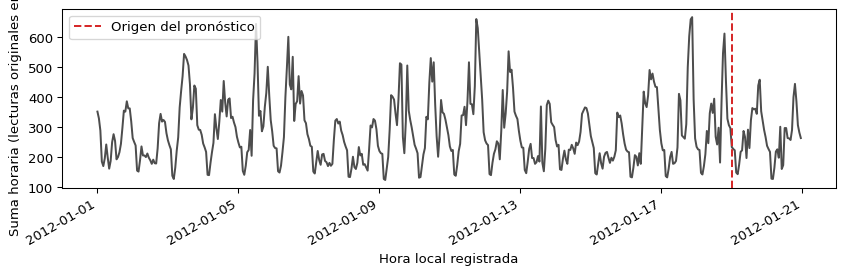

In [3]:
# Keep the reserved final block visible without passing it into the fit.
fig, ax = plt.subplots()
ax.plot(times, y, color="0.3")
ax.axvline(times[cut], color="tab:red", linestyle="--", label=words["cut"])
ax.set(xlabel=words["time"], ylabel=words["value"])
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


## Método

### Copiar el último ciclo diario observado

Sea una historia indexada desde cero hasta T−1, sea m el número de lecturas por ciclo y sea j el índice de anticipación contado desde cero. La trayectoria puntual que repite el ciclo es

$$
\widehat y_{T+j}=y_{T-m+(j\bmod m)},\qquad j=0,\ldots,H-1.
$$

T representa la longitud del prefijo, H el horizonte solicitado y el resto de la división vuelve a recorrer el último ciclo observado. Con m=24 y H=48, mañana y pasado mañana repiten el mismo último día. No aparece una tendencia nueva ni un efecto de fin de semana salvo que ya esté representado en ese perfil. La interpretación requiere historia suficiente: el paquete utiliza una referencia ingenua de un paso cuando la historia disponible es más corta que el ciclo solicitado.

Primero inicializamos un objeto nuevo con el prefijo disponible. Solicitar las probabilidades 0.1, 0.5 y 0.9 devuelve una matriz H por tres cuyas columnas mantienen ese orden. La columna mediana coincide exactamente con la trayectoria copiada. La primera fila impresa concreta la interfaz y su comparación con `history[-24]` aporta un valor independiente que puede leerse a mano. Así se comprueba una consecuencia de la fórmula sin sustituir el paquete por otro algoritmo de pronóstico escrito dentro del cuaderno.


In [4]:
# Start from the prefix, then request all three quantile columns together.
model = SeasonalNaive(seasonality=m, widen=True)
model.start(history)
q = model.predict(horizon, [0.1, 0.5, 0.9])
assert q.shape == (horizon, 3) and np.isfinite(q).all()
assert (np.diff(q, axis=1) >= 0).all()
print("first predicted row:", np.round(q[0], 4))
print("manual first point / package median:", history[-m], q[0, 1])
assert q[0, 1] == history[-m]


first predicted row: [135.6989 234.4086 380.9678]
manual first point / package median: 234.4086 234.4086


### Interpretar la banda empírica sin suponer calibración

El paquete forma residuos estacionales históricos r_i=y_i−y_{i−m}. Calcula sus cuantiles empíricos y resta su mediana empírica, de modo que el desplazamiento de probabilidad 0.5 sea cero. Con el ensanchamiento habilitado, el cuantil pronosticado es

$$
q_{T+j}(p)=\widehat y_{T+j}+\sqrt{j+1}\,[Q_p(r)-Q_{0.5}(r)].
$$

Q_p denota el cuantil muestral de probabilidad p y r la muestra de residuos disponible antes del origen. El factor de raíz cuadrada es una decisión de implementación para ampliar la dispersión con la anticipación. No es un teorema sobre la distribución condicional de este cliente eléctrico. La dependencia de los residuos, los cambios de rutina y la varianza desigual pueden alejar la cobertura del 80 por ciento nominal. Restar la mediana también permite que residuos asimétricos produzcan distancias distintas entre la mediana y los límites inferior y superior.

La implementación almacena la historia acumulada y vuelve a calcular cuantiles de residuos al predecir. Su protocolo admite actualizaciones secuenciales, pero este ejemplo no demuestra predicción de costo constante ni una arquitectura recurrente nativa. La distinción importa al interpretar tiempos: disponer de un método `ingest` no basta para establecer que el costo total de cada llegada sea independiente de la longitud histórica.

### Separar el error de su escala

Todos los candidatos del experimento de sensibilidad comparten una escala de diferencias estacionales calculada en las primeras W=96 observaciones, con período de referencia 24:

$$
s={1\over W-m}\sum_{i=m}^{W-1}|y_i-y_{i-m}|,\qquad
\operatorname{MASE}={\operatorname{promedio}|y-\widehat y|\over s}.
$$

El error del numerador utiliza observaciones posteriores. El denominador emplea solamente el prefijo inicial declarado y no cambia entre candidatos. Si ese prefijo fuera perfectamente periódico, s podría ser cero y la razón quedaría indefinida; la lección rechaza ese caso en vez de introducir una constante pequeña arbitraria. Un MASE menor que uno indica un error inferior a esta escala histórica. Por sí solo no demuestra haber superado otro pronóstico en el bloque futuro ni expresa un costo monetario.


fixed warmup scale: 73.506574
48-step MAE / MASE / interval coverage: 60.439075 0.822227 1.000000


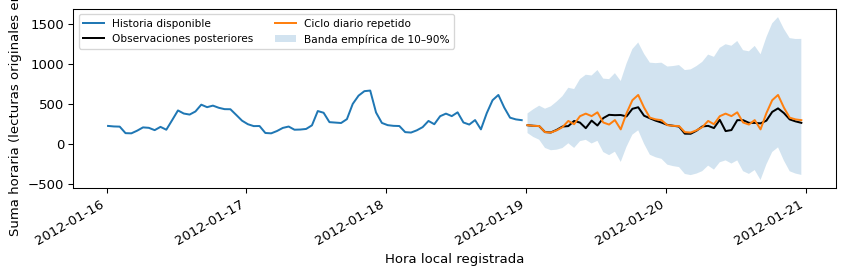

In [5]:
# Fix the historical scale once; the target is used only after prediction.
scale = seasonal_naive_mae(y[:warmup], m)
if scale <= 0:
    raise ValueError("The warmup seasonal error scale must be positive")
mae = float(np.mean(np.abs(actual - q[:, 1])))
coverage = float(np.mean((actual >= q[:, 0]) & (actual <= q[:, 2])))
print("fixed warmup scale:", f"{scale:.6f}")
print("48-step MAE / MASE / interval coverage:", f"{mae:.6f}", f"{mae/scale:.6f}", f"{coverage:.6f}")
fig, ax = plt.subplots()
ax.plot(times[cut-72:cut], history[-72:], label=words["history"])
ax.plot(times[cut:], actual, color="black", label=words["actual"])
ax.plot(times[cut:], q[:, 1], label=words["forecast"])
ax.fill_between(times[cut:], q[:, 0], q[:, 2], alpha=.2, label=words["interval"])
ax.set(xlabel=words["time"], ylabel=words["value"])
ax.legend(ncol=2, fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


La segunda figura coloca el perfil repetido, las observaciones posteriores y la banda empírica sobre ejes comunes. Conviene leer la alineación de fase antes que el ancho del intervalo: una banda amplia puede esconder un máximo mal ubicado y aun mostrar cobertura aceptable. El MAE conserva las unidades aritméticas del extracto; MASE ofrece una descripción sin escala; la cobertura cuenta qué fracción de los 48 objetivos cae entre los extremos. Son cantidades complementarias. En anticipaciones posteriores la banda incluso baja de cero: esta construcción de residuos no impone la no negatividad física de las lecturas eléctricas, y su cobertura completa debe interpretarse junto a ese ancho excesivo. El pronóstico por bloque se emite una vez y sus anticipaciones posteriores no incorporan verdades que llegan dentro del bloque reservado.

### Sensibilidad al ciclo supuesto

Ahora cambiamos la pregunta y emitimos pronósticos secuenciales de un paso después del mismo prefijo inicial. En cada origen, el evaluador predice, calcula el error frente al siguiente valor y solo entonces lo revela mediante `ingest`. Cada modelo recibe las mismas observaciones en el mismo orden. Esto difiere del pronóstico anterior de 48 pasos: las predicciones posteriores de un paso ya disponen de verdades intermedias. Sus medidas no deben presentarse como si utilizaran el mismo conjunto de información que aquel bloque.

Los períodos 1, 12, 24 y 48 representan persistencia, copia de medio día, copia diaria y copia de dos días. `Stream` mantiene su estacionalidad métrica en 24 para todos. De lo contrario, cambiar el período del modelo modificaría también el denominador de MASE y mezclaría una predicción diferente con una regla de medición diferente. Las escalas impresas permiten comprobar si este control experimental se mantiene en cada resultado devuelto. Los cuatro candidatos pronostican las mismas llegadas y sus barras son comparables dentro de este experimento.


scales for all model periods: [73.506574, 73.506574, 73.506574, 73.506574]
period / forecasts / MASE / coverage: 1 384 0.651717 0.744792
period / forecasts / MASE / coverage: 12 384 1.972140 0.760417
period / forecasts / MASE / coverage: 24 384 0.891215 0.799479
period / forecasts / MASE / coverage: 48 384 1.102410 0.807292


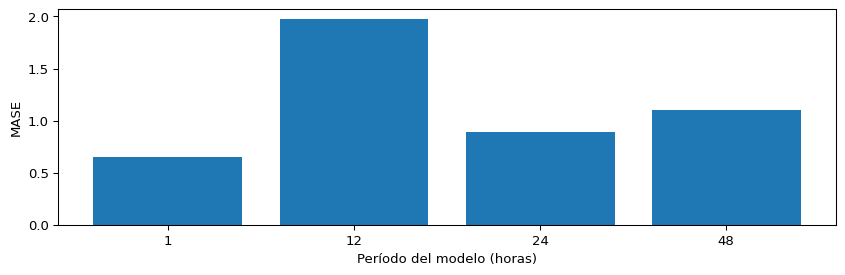

In [6]:
# Change only the model period, keeping the stream and metric period fixed.
periods = (1, 12, 24, 48)
stream = Stream(y, seasonality=m, name="MT_010-hourly-sum")
results = [run_prequential(SeasonalNaive(p), stream, horizon=1, warmup=warmup) for p in periods]
print("scales for all model periods:", [round(r.scale, 6) for r in results])
for p, r in zip(periods, results, strict=True):
    print("period / forecasts / MASE / coverage:", p, len(r.cutoffs),
          f"{np.mean(r.mase):.6f}", f"{np.mean(r.coverage):.6f}")
fig, ax = plt.subplots()
ax.bar([str(p) for p in periods], [np.mean(r.mase) for r in results])
ax.set(xlabel=words["period"], ylabel="MASE")
fig.tight_layout()
plt.show()


La tercera figura presenta el MASE promedio a un paso según el período del modelo. Una barra menor aporta evidencia descriptiva para este cliente y este extracto. Como se ha inspeccionado el período más favorable utilizando estos resultados, desplegarlo como modelo seleccionado exigiría evaluarlo en un período posterior intacto. La repetición diaria puede perder frente a persistencia si horas adyacentes se parecen más que horas correspondientes de días distintos. Persistencia, a su vez, puede retrasarse frente al ascenso de un máximo diario recurrente. El orden observado debe explicarse a partir de la serie, sin eliminar candidatos que resulten inconvenientes.

### Límites ante un cambio de nivel

Para aislar el retraso de adaptación, agregamos después del origen una constante igual a dos veces la escala histórica fija. Ambos modelos secuenciales parten de la misma historia sin modificar. Uno recibe el futuro original; el otro recibe el futuro desplazado después de cada predicción. Durante el primer ciclo diario, el segundo sigue copiando valores anteriores a la intervención. Cuando ha llegado un ciclo completo, tanto su objetivo actual como la referencia copiada contienen la constante y esta se cancela en la diferencia.


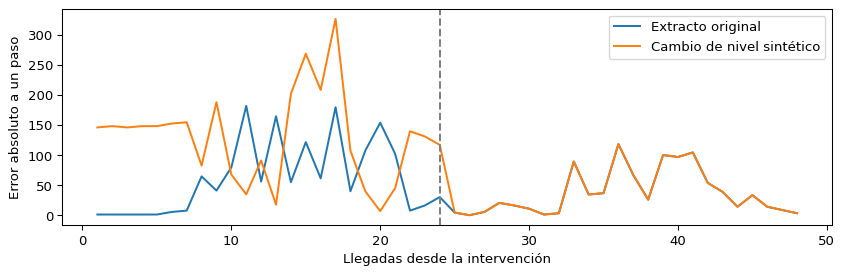

added level: 147.013147
mean absolute errors, first cycle: 61.648754 129.793906
post-cycle error-path difference: 0.00000000


In [7]:
# A declared synthetic intervention isolates the lag after a level change.
shift = 2 * scale
changed = y.copy()
changed[cut:] += shift
original_model, changed_model = SeasonalNaive(m), SeasonalNaive(m)
original_model.start(history)
changed_model.start(history)
original_errors, changed_errors = [], []
for t in range(cut, len(y)):
    original_errors.append(abs(y[t] - original_model.predict(1, [0.5])[0, 0]))
    changed_errors.append(abs(changed[t] - changed_model.predict(1, [0.5])[0, 0]))
    original_model.ingest(y[t:t+1])
    changed_model.ingest(changed[t:t+1])
fig, ax = plt.subplots()
ax.plot(np.arange(1, horizon+1), original_errors, label=words["original"])
ax.plot(np.arange(1, horizon+1), changed_errors, label=words["shift"])
ax.axvline(m, color="0.5", linestyle="--")
ax.set(xlabel=words["arrival"], ylabel=words["absolute"])
ax.legend()
fig.tight_layout()
plt.show()
print("added level:", f"{shift:.6f}")
print("mean absolute errors, first cycle:",
      f"{np.mean(original_errors[:m]):.6f}", f"{np.mean(changed_errors[:m]):.6f}")
print("post-cycle error-path difference:",
      f"{np.max(np.abs(np.array(original_errors[m:])-np.array(changed_errors[m:]))):.8f}")


La cuarta figura muestra errores absolutos frente al número de llegadas desde la intervención. La línea vertical identifica un ciclo diario completo y no un punto de cambio estimado. Agregar nivel no garantiza aumentar el error absoluto en cada llegada temprana: el desplazamiento podría cancelar temporalmente un error de signo contrario. Después del ciclo, la diferencia entre ambas trayectorias de error debe ser cero salvo precisión numérica, porque la intervención es constante y la regla copia un rezago de 24. Un cambio real también puede alterar forma, varianza o fase; entonces no tiene por qué ocurrir esta cancelación exacta. El ejercicio controlado explica un límite de la regla y no acredita un detector robusto de cambios.

### Úsalo con tus propios datos

Prepara un valor numérico finito por marca temporal ordenada y equiespaciada. Resuelve duplicados, vacíos, horario de verano y agregaciones antes de interpretar un rezago de filas como tiempo transcurrido. Elige m mediante una hipótesis temporal sustantiva y conserva suficientes ciclos completos para estimar residuos. Entrega solo observaciones disponibles en el origen a `SeasonalNaive(...).start(prefix)` y después llama `predict(H, [0.1, 0.5, 0.9])`. Revisa forma, finitud y orden de cuantiles antes de consumir la salida.

En una aplicación secuencial, emite el pronóstico antes de llamar `ingest` con observaciones recién reveladas. Mantén separadas la política de llegada y la anticipación del pronóstico. Registra el prefijo inicial, el período métrico, el período del modelo y los niveles de cuantiles como campos distintos de configuración. Las columnas CSV aportan identidad, orden y valores; por sí solas no especifican política de datos faltantes, pérdida operacional o contrato de covariables futuras. Explicita esas decisiones al extender la aplicación.


## Resultados

**Respuesta:** La copia diaria obtiene un MASE de 0.822227 a 48 pasos y contiene todos los valores reservados dentro de su banda. En la predicción secuencial a un paso, persistencia presenta el menor MASE observado, 0.651717, frente a 0.891215 de la referencia diaria. La copia de medio día obtiene el peor resultado, 1.972140. La continuidad de corto plazo explica mejor este extracto a un paso que exigir una coincidencia diaria. La banda amplia del horizonte largo alcanza cobertura completa del bloque sin establecer calibración al 80 por ciento. Tras intervenir el nivel con una constante, ambas trayectorias de error vuelven a coincidir cuando ha llegado un ciclo diario completo, como predice el mecanismo de rezago.

Todos los números se calculan en las celdas ejecutadas. Lee MAE y cobertura del origen fijo junto a la figura de 48 pasos, y las barras de período junto a la escala inicial común. Sus protocolos difieren; comparar directamente sus magnitudes no constituye un enfrentamiento equivalente. La intervención de nivel agrega una perturbación conocida y describe su efecto por separado de las mediciones auténticas. Ninguna comparación estima generalización entre clientes, cobertura calibrada bajo cambios arbitrarios ni ahorro en una decisión de planificación eléctrica.


## Resumen

Repetir un ciclo constituye una explicación útil cuando son visibles la convención temporal, el período de referencia y el límite de información. La trayectoria puntual se inspecciona fácilmente; el intervalo de residuos todavía necesita evaluación empírica. La siguiente lección estudia otra cuestión: cómo un ciclo terminal incompleto cambia la alineación en modelos con estados estacionales explícitos. Conserva la distinción entre predicción, llegada y escala de evaluación al comparar esos pronósticos más elaborados.


## Referencias

- Trindade, ElectricityLoadDiagrams20112014, conjunto UCI y convenciones de origen: https://doi.org/10.24432/C58C86
- Hyndman y Athanasopoulos, Forecasting: Principles and Practice, referencias estacionales y evaluación: https://otexts.com/fpp3/toolbox.html
- Hyndman y Koehler, Another look at measures of forecast accuracy: https://doi.org/10.1016/j.ijforecast.2006.03.001
- PreqTS 0.3.0, paquete publicado utilizado en esta lección: https://pypi.org/project/preqts/0.3.0/
